---
title: 3.6.b Amenaza — Lluvias intensas y vendavales
short_title: b. Amenaza
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/sincelejo/blob/main/book/03_analisis/36_lluvias_vendavales/b_amenaza.ipynb)

**Reproducible sin red en el checkout.** La fuente preservada y sus limitaciones se describen en el capítulo 2.3.


In [1]:
from pathlib import Path
import sys, subprocess, json
candidatos = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidatos if (p/'src/sincelejo/analisis.py').exists()), None)
if ROOT is None:
    ROOT = Path('/content/sincelejo')
    if not ROOT.exists():
        subprocess.run(['git','clone','https://github.com/mromerot/sincelejo.git',str(ROOT)],check=True)
    subprocess.run([sys.executable,'-m','pip','install','-q','-e',str(ROOT)+'[libro]'],check=True)
sys.path.insert(0,str(ROOT/'src'))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sincelejo.analisis import cargar, indicadores, deficit_trimestral, sensibilidad_calor
clima = cargar(ROOT/'data/raw/power_1991_2025.json')
anual = indicadores(clima)
evidencia = pd.read_json(ROOT/'data/evidencia.json')
plt.rcParams.update({'figure.figsize':(9,4), 'axes.spines.top':False, 'axes.spines.right':False})


## Método

Se muestran lluvia extrema diaria y velocidad media diaria máxima de cada año por separado. Para daños por viento se requieren ráfagas de duración conocida y funciones de fragilidad compatibles. No se convierte un promedio diario en ráfaga mediante un factor universal.

,rx1day,r20,viento_dia_max
anio,,,
1991,28.50,1,4.30
1992,32.05,3,4.02
1993,77.98,14,4.28
1994,36.58,10,3.59
1995,40.33,7,3.99
1996,31.90,3,5.07
1997,26.74,7,3.52
1998,43.55,9,4.26
1999,34.01,6,3.69


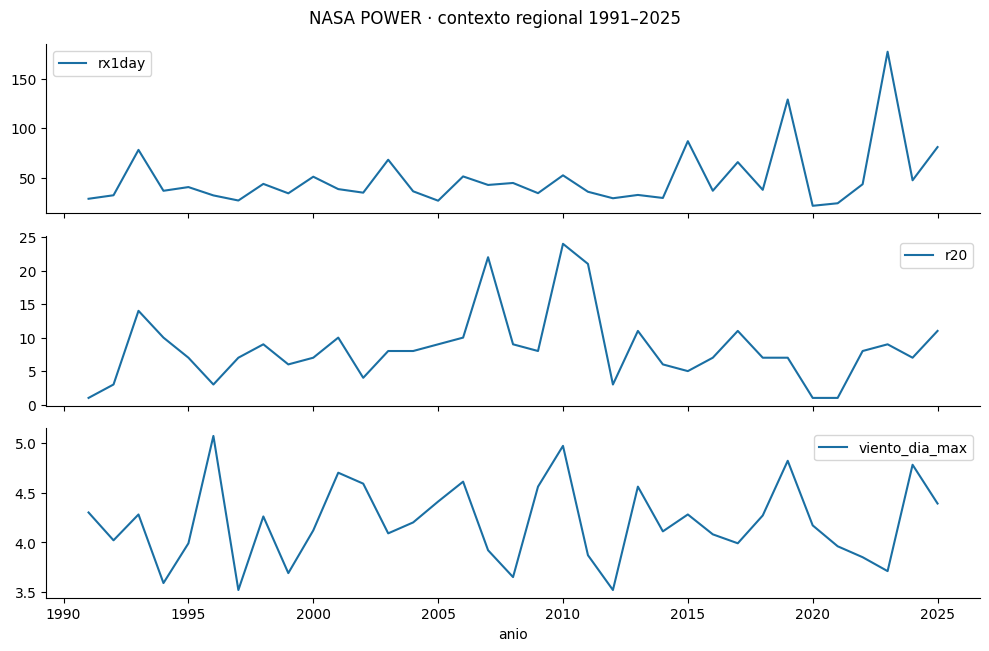

In [2]:
columnas = ['rx1day', 'r20', 'viento_dia_max']
display(anual[columnas].round(2))
anual[columnas].plot(subplots=True,figsize=(10,6.6000000000000005),color='#1a6fa3',legend=True)
plt.suptitle('NASA POWER · contexto regional 1991–2025'); plt.tight_layout(); plt.show()

## Interpretación

El libro presenta contexto meteorológico y una ruta de inspección. No establece velocidades de diseño, periodos de retorno de ráfagas ni un historial completo de vendavales.

Para el vínculo con exposición y vulnerabilidad continúe con [riesgo](c_riesgo.ipynb).